# Isochrons 03. One hundred reduced Hodgkin-Huxley isochrons by continuation (the paper's Figure 2)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/isochrons/03_HH_isochrons-by-continuation.ipynb)

Notebook 02 computed 100 FitzHugh-Nagumo isochrons by the continuation method of
Osinga & Moehlis (SIAM J. Appl. Dyn. Syst. 9, 2010). Here the same code runs on the
model of the paper itself, the **reduced Hodgkin-Huxley neuron** (its eq. 4.1), and
reproduces its Figure 2: 100 isochrons θ_i = i/100, each **a one-parameter family of
orbit segments of a boundary value problem, followed by continuation in XPPAUT 8.2's
AUTO**, stage by stage up to the time-4T map. Compared with notebook 02, only the vector
field and a few scales change.

| step | what | XPP / AUTO |
|---|---|---|
| 1 | the model, the orbit Γ, its period T and phase zero γ0 (maximum of v) | Initialconds > Go, Periodic |
| 2 | the isochron's direction n_s at γ(θ), perpendicular to the adjoint | Numerics > Averaging > New adj |
| 3 | the BVP: segments u' = kT F(u) on [0, 1] with u(1) = γ + δ n_s | an .ode file with two `bndry` lines |
| 4 | stage 1: start from Γ (δ = 0), continue in δ until abs(δ) = η | Run > Bdry Value, then continuation |
| 5 | stages k = 2, 3, …: start from the last segment followed by one period of Γ | the paper's concatenation (3.5) |
| 6 | all 100 phases θ_i = i/100, inside and outside Γ | in parallel, one XPPAUT per process |
| 7 | checks: against the brute-force phase, and no crossings | |

Computing all 100 isochrons takes about 4.5 core-hours (see the Settings). The results
are also stored with the notebook (`data/03_HH_isochrons.npz`), so by default the
notebook computes the 0-phase isochron live (about 5 minutes) and loads the other 99.

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp tqdm --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

## Settings

* `COMPUTE_ALL = True` recomputes all 100 isochrons (2 to 6 minutes each, about 4.5
  core-hours; with `N_WORKERS` processes it is that many times faster). `False` computes the 0-phase
  isochron and loads the stored results for the rest.
* `KMAX`: stages inside Γ (time-k T maps). `KOUT`: stages outside.

In [2]:
COMPUTE_ALL = False
N_WORKERS = 4                     # processes for COMPUTE_ALL (each runs its own XPPAUT)
KMAX, KOUT = 4, 1                 # the paper: up to the time-4T map inside, 1 stage outside
NPHASE = 100
STORED = "data/03_HH_isochrons.npz"
STORED_URL = "https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/data/03_HH_isochrons.npz"

In [3]:
import json
import multiprocessing as mp
import os
import tempfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path as Polygon
from pyxpp.builder import ModelBuilder
from tqdm.auto import tqdm

WORK = Path(tempfile.mkdtemp())
plt.rcParams.update({"figure.dpi": 100})

## 1. The model, the orbit Γ, the period T and phase zero

$$\dot V = I - \bar g_{Na} m_\infty(V)^3 (0.8 - n)(V - V_{Na}) - \bar g_K n^4 (V - V_K) - g_L (V - V_L),
\qquad \dot n = \alpha_n(V)(1-n) - \beta_n(V)\, n$$

with the classical rate functions, I = 10, ḡ_Na = 120, ḡ_K = 36, g_L = 0.3, V_Na = 50,
V_K = −77, V_L = −54.4. Phase zero γ0 is the maximum of V on Γ (there V' = 0), found by
bisection on the time.

In [4]:
FUN = [("am(v)", "0.1*(v+40)/(1-exp(-(v+40)/10))"), ("bm(v)", "4*exp(-(v+65)/18)"),
       ("an(v)", "0.01*(v+55)/(1-exp(-(v+55)/10))"), ("bn(v)", "0.125*exp(-(v+65)/80)"),
       ("minf(v)", "am(v)/(am(v)+bm(v))")]
FV = "iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)"
FW = "an(v)*(1-n)-bn(v)*n"
PARS = dict(iapp=10, gna=120, gk=36, gl=0.3, ena=50, ek=-77, el=-54.4)
OPTS = dict(meth="rk4", bound=1e4, jac_eps=1e-7, newt_tol=1e-10)
SC = np.array([100.0, 1.0])                        # V and n scaled to similar sizes, for distances only

mb = ModelBuilder("reduced_hh")
for sig, expr in FUN:
    mb.function(sig, expr)
mb = (mb.ode("v", FV).ode("n", FW).parameter(**PARS).initial(v=-60, n=0.3)
      .option(total=300, dt=0.01, maxstor=400000, **OPTS))
print(mb.render())
m = mb.load(WORK / "reduced_hh.ode")
m.run()                                            # XPP: Initialconds > Go
m.buttons.xi_vs_t("v")
m.buttons.initialconds.periodic()                  # XPP: Initialconds > Periodic -> total = T
T = m.numerics["total"]


def flow(x, t, dt=1e-4):
    """Phi(t, x) by XPP (RK4 with a step of at most dt that divides t)"""
    m.set(v=x[0], n=x[1])
    m.run(keep=False, total=t, dt=t / max(1, int(np.ceil(t / dt))), trans=0)
    s = m.last_state()
    return np.array([s["V"], s["N"]])


g = flow(np.array([m.ics["V"], m.ics["N"]]), T - 0.05)
a, b = 0.0, 0.1
for _ in range(40):                                # bisection for V' = 0 at the top of the spike
    c = 0.5 * (a + b)
    a, b = (c, b) if m.rhs(flow(g, c))["V"] > 0 else (a, c)
gamma0 = flow(g, 0.5 * (a + b))
m.set(v=gamma0[0], n=gamma0[1])
orb = m.run(keep=False, total=T, dt=0.001, trans=0)
POLY = np.c_[orb["v"], orb["n"]]
eq = m.equilibrium({"v": -60, "n": 0.4})
xstar = np.array([eq.x["V"], eq.x["N"]])
# Floquet multiplier from Liouville's formula: mu = exp( integral of div F ), div F from XPP's right-hand side
e = 1e-6
divF = np.array([(m.rhs((x[0] + e, x[1]))["V"] - m.rhs((x[0] - e, x[1]))["V"]) / (2 * e)
                 + (m.rhs((x[0], x[1] + e))["N"] - m.rhs((x[0], x[1] - e))["N"]) / (2 * e) for x in POLY[::5]])
mu_log = float(np.trapezoid(divF, np.asarray(orb.t)[::5]))
print(f"T = {T:.6f} (paper 11.8463); gamma0 = ({gamma0[0]:.6f}, {gamma0[1]:.6f}) (paper (44.7064, 0.4597)); "
      f"x* = ({xstar[0]:.4f}, {xstar[1]:.4f})")
print(f"integral of div F over one period = {mu_log:.3f}, so the multiplier mu = {np.exp(mu_log):.2e}")

am(v)=0.1*(v+40)/(1-exp(-(v+40)/10))
bm(v)=4*exp(-(v+65)/18)
an(v)=0.01*(v+55)/(1-exp(-(v+55)/10))
bn(v)=0.125*exp(-(v+65)/80)
minf(v)=am(v)/(am(v)+bm(v))
v'=iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)
n'=an(v)*(1-n)-bn(v)*n
par iapp=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4
init v=-60,n=0.3
@ total=300,dt=0.01,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



T = 11.846275 (paper 11.8463); gamma0 = (44.706382, 0.459736) (paper (44.7064, 0.4597)); x* = (-59.6044, 0.4026)
integral of div F over one period = -46.411, so the multiplier mu = 6.99e-21


The multiplier is μ ≈ e^(−46.5) ≈ 7 × 10⁻²¹ (the paper's model is even more strongly
slow-fast than FitzHugh-Nagumo with μ ≈ 2 × 10⁻¹⁷): far below anything backward
integration could resolve in double precision.

## 2. The direction n_s of the isochron at γ(θ)

XPP's adjoint Z(t) is the gradient of the asymptotic phase along Γ; the isochron is
perpendicular to it: n_s = (Z_n, −Z_V)/|Z|, oriented to point out of Γ.

In [5]:
A = m.buttons.numerics.averaging                   # XPP: Numerics > Averaging > New adj
A.parameters(6400)
A.new_adj()
adj = m.data


def phase_point(theta):
    gth = gamma0.copy() if theta == 0 else flow(gamma0, theta * T)
    zv, zw = np.interp(theta * T, adj.t, adj["v"]), np.interp(theta * T, adj.t, adj["n"])
    ns = np.array([zw, -zv]) / np.hypot(zv, zw)
    f = m.rhs(gth)
    if f["V"] * ns[1] - f["N"] * ns[0] > 0:        # make n_s point out of Gamma
        ns = -ns
    return gth, ns


print("theta = 0: n_s =", phase_point(0.0)[1])

theta = 0: n_s = [ 9.99999991e-01 -1.37107891e-04]


## 3. The boundary value problem, as an XPP .ode file

Orbit segments of length per = kT, with time rescaled to [0, 1], that end on the short
straight piece L_η = {γ + δ n_s, |δ| ≤ η} of the isochron. `v'` in a `bndry` line means
v at the right end. u(0) is free, so continuation in d = δ gives a one-parameter family,
and **the start point u(0) of every member is a point of the isochron** (it reaches the
isochron's linear piece after exactly k periods).

In [6]:
ETA, DS = 1e-4, 1e-5                               # the paper's eta and DS = 0.1 eta
NTST_GAMMA = 100                                   # mesh intervals per period; stage k uses 100 k
AUTO_NUM = dict(ncol=4, dsmin=1e-8, dsmax=0.1, epsl=1e-8, epsu=1e-8, epss=1e-6,
                itmx=8, itnw=5, nwtn=3, iad=3, normmax=1e6, npr=100000)
NMX = 5000
WINDOW = (-150.0, 150.0, 0.15, 0.95)               # the outside branch is followed until it leaves this
PLOT = (-90, 52, 0.3, 0.8)                          # the window of the paper's Figure 2


def bvp_builder():
    bb = ModelBuilder("hh_isochron_bvp")
    bb.comment("orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s")
    for sig, expr in FUN:
        bb.function(sig, expr)
    return (bb.ode("v", f"per*({FV})").ode("n", f"per*({FW})")
            .parameter(**PARS).parameter(per=T, gv=0, gn=0, tv=1, tn=0, d=0)
            .boundary("v'-gv-d*tv").boundary("n'-gn-d*tn")
            .option(total=1, dt=1e-4, maxstor=400000, **OPTS))


g0, ns0 = phase_point(0.0)
print(bvp_builder().render().replace("gv=0,gn=0,tv=1,tn=0,d=0",
                                     f"gv={g0[0]:.10g},gn={g0[1]:.10g},tv={ns0[0]:.10g},tn={ns0[1]:.10g},d=0"))


def load_bvp():
    B = bvp_builder().load(Path(tempfile.mkdtemp()) / "hh_isochron_bvp.ode")
    B.auto.parameters("d", "per")
    return B

# orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s
am(v)=0.1*(v+40)/(1-exp(-(v+40)/10))
bm(v)=4*exp(-(v+65)/18)
an(v)=0.01*(v+55)/(1-exp(-(v+55)/10))
bn(v)=0.125*exp(-(v+65)/80)
minf(v)=am(v)/(am(v)+bm(v))
v'=per*(iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el))
n'=per*(an(v)*(1-n)-bn(v)*n)
par iapp=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4
par per=11.846275030774093,gv=44.70638155,gn=0.4597360195,tv=0.9999999906,tn=-0.0001371078909,d=0
bndry v'-gv-d*tv
bndry n'-gn-d*tn
@ total=1,dt=0.0001,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



## 4–5. Algorithm Isochron

* **Start a stage** (AUTO: *Run > Bdry Value* from a given solution). Stage 1 starts from
  Γ itself (δ = 0). XPP's AUTO puts the starting solution on a uniform mesh, so a few
  steps with δ unbounded let the mesh adapt before the real continuation.
* **Choose the direction** by probing a few steps each way: inside or outside Γ at stage
  1; at stage k > 1, the way that extends the isochron (the other way goes back over the
  previous stage).
* **Continue in δ** until |δ| = η. Every point's u(0) is an isochron point.
* **Next stage**: the last segment (k−1 periods) followed by one period of Γ, rescaled to
  [0, 1] (the paper's eq. 3.5), with per = kT and NTST = 100k.

In [7]:
class Isochron:
    def __init__(self, B, gth, ns):
        self.B, self.g, self.ns = B, gth, ns
        self.poly = Polygon(POLY)
        self.log = []
        B.set(per=T, v=gth[0], n=gth[1], d=0)      # stage 1 starts from Gamma, from gamma, over one period
        tr = B.run(total=1, dt=1e-4)
        self.uG = np.asarray(tr.t, float), np.c_[tr["v"], tr["n"]].astype(float)

    @staticmethod
    def pts(points):
        return np.array([[p.u0["v"], p.u0["n"], p.par["d"]] for p in points]).reshape(-1, 3)

    def start(self, k, initial):
        for ntst, itnw in [(NTST_GAMMA * k, 5), (NTST_GAMMA * k, 20), (2 * NTST_GAMMA * k, 20),
                           (4 * NTST_GAMMA * k, 20)]:
            self.B.set(per=k * T, gv=self.g[0], gn=self.g[1], tv=self.ns[0], tn=self.ns[1], d=0)
            self.B.auto.reset()
            first = self.B.auto.run("d", start="bdry value", initial=initial, ntst=ntst, ds=DS, nmax=6,
                                    parmin=-1, parmax=1, **dict(AUTO_NUM, itnw=itnw, dsmax=1e-6))
            if len(first) == 6 and all(p.type != "MX" for p in first) and abs(first[-1].par["d"]) < ETA / 10:
                return first[-1], ntst, itnw
            self.log.append(f"k={k}: start with NTST={ntst}, ITNW={itnw} failed")
        raise RuntimeError(f"k={k}: AUTO did not converge from the starting solution")

    def delta_back(self, sol, k):
        """delta' = (u((k-1)/k) - gamma) . n_s: where the segment is one period before its end"""
        t, U = sol
        tt = (k - 1) / k
        j = int(np.clip(np.searchsorted(t, tt) - 2, 0, len(t) - 4))
        ts, Us = t[j:j + 4], U[j:j + 4]
        w = np.array([np.prod([(tt - ts[q]) / (ts[l] - ts[q]) for q in range(4) if q != l]) for l in range(4)])
        return float((w @ Us - self.g) @ self.ns)

    def score(self, u, k, direction, probe, d0):
        if k == 1:                                  # stage 1: does the probe go inside (or outside) Gamma?
            last = u[-max(3, len(u) // 4):, :2]
            far = last[np.hypot(*((last - self.g) / SC).T) > 1e-2]
            return 0.0 if len(far) == 0 else (self.poly.contains_points(far).mean() - 0.5) * (-direction)
        d1 = self.delta_back(probe[-1].solution, k)  # stage k > 1: does |delta'| grow (extend)?
        return (abs(d1) - abs(d0)) / abs(d0)

    def stage(self, k, direction, initial, nprobe=25):
        B, t0 = self.B, time.time()
        p0, ntst, itnw = self.start(k, initial)
        d0 = self.delta_back(p0.solution, k) if k > 1 else None
        scores = {}
        for n_try in (nprobe, 6 * nprobe):
            for sign in (1, -1):
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
                scores[sign] = self.score(u, k, direction, probe, d0)
                if scores[sign] > 0.01:
                    break
            else:
                sign = max(scores, key=scores.get)
                if scores[sign] <= 0:
                    continue
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
            break
        else:
            raise RuntimeError(f"k={k}: neither direction goes the requested way {scores}")
        parts, last = [u], probe[-1]
        chunk = NMX if direction < 0 else 100
        while abs(last.par["d"]) < ETA and last.type != "MX" and sum(map(len, parts)) < NMX:
            x0, x1, y0, y1 = WINDOW
            if direction > 0 and not (x0 < last.u0["v"] < x1 and y0 < last.u0["n"] < y1):
                break                               # the outside branch has left the window
            more = B.auto.run(grab=last.label, ds=sign * DS, nmax=min(chunk, NMX - sum(map(len, parts))),
                              parmin=-ETA, parmax=ETA, **AUTO_NUM)
            if len(more) <= 1:
                break
            parts.append(self.pts(more)[1:])
            last = more[-1]
        u = np.vstack(parts)
        info = dict(k=k, side="in" if direction < 0 else "out", ntst=ntst, points=len(u),
                    d_end=float(last.par["d"]), seconds=round(time.time() - t0, 1))
        self.log.append(json.dumps(info))
        return u, last.solution, info

    def concatenate(self, k, sol):
        """eq. (3.5): the last segment (k-1 periods) followed by one period of Gamma, on [0, 1]"""
        (ts, Us), (tG, UG) = sol, self.uG
        tt = np.linspace(0, 1, 4000 * k + 1)
        a = tt <= (k - 1) / k
        U = np.empty((len(tt), 2))
        for j in range(2):
            U[a, j] = np.interp(tt[a] * k / (k - 1), ts, Us[:, j])
            U[~a, j] = np.interp(tt[~a] * k - (k - 1), tG, UG[:, j])
        return tt, U

    def run(self, kmax, kout, bar=None):
        res = {}
        for direction, kk in ((-1, kmax), (+1, kout)):
            init = self.uG
            for k in range(1, kk + 1):
                u, sol, info = self.stage(k, direction, init)
                res[(info["side"], k)] = u
                if bar is not None:
                    bar.set_postfix(stage=f"{info['side']} k={k}", points=info["points"], NTST=info["ntst"])
                    bar.update(1)
                if k < kk:
                    init = self.concatenate(k + 1, sol)
        return res

### The 0-phase isochron, live

Stage by stage, printed as it goes.

θ = 0:   0%|          | 0/5 [00:00<?, ?stage/s]

{"k": 1, "side": "in", "ntst": 100, "points": 718, "d_end": -0.00010028932107226643, "seconds": 7.5}
k=2: start with NTST=200, ITNW=5 failed
{"k": 2, "side": "in", "ntst": 200, "points": 808, "d_end": -0.00010215720288919538, "seconds": 33.1}
k=3: start with NTST=300, ITNW=5 failed
k=3: start with NTST=300, ITNW=20 failed
k=3: start with NTST=600, ITNW=20 failed
{"k": 3, "side": "in", "ntst": 1200, "points": 751, "d_end": -0.00010053172818015527, "seconds": 217.2}
k=4: start with NTST=400, ITNW=5 failed
{"k": 4, "side": "in", "ntst": 400, "points": 677, "d_end": -0.00010374054899117729, "seconds": 63.1}
{"k": 1, "side": "out", "ntst": 100, "points": 124, "d_end": -1.5659193175847196e-09, "seconds": 1.9}


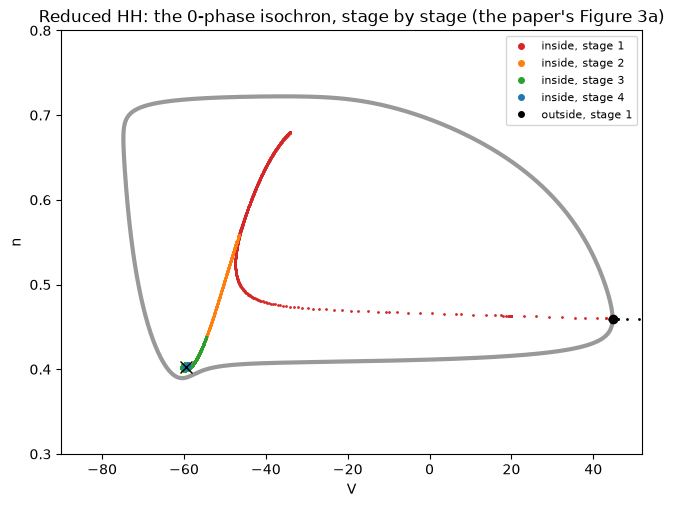

In [8]:
B = load_bvp()
with tqdm(total=KMAX + KOUT, desc="θ = 0", unit="stage") as bar:
    iso0 = Isochron(B, g0, ns0)
    res0 = iso0.run(KMAX, KOUT, bar=bar)
for line in iso0.log:
    print(line)

cols = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(POLY[:, 0], POLY[:, 1], color="0.6", lw=3)
for (side, k), u in res0.items():
    ax.plot(u[:, 0], u[:, 1], ".", ms=2, color=cols[k - 1] if side == "in" else "k",
            label=f"{'inside' if side == 'in' else 'outside'}, stage {k}")
ax.plot(*g0, "ko"); ax.plot(*xstar, "x", color="k", ms=9)
ax.set(xlim=PLOT[:2], ylim=PLOT[2:], xlabel="V", ylabel="n", title="Reduced HH: the 0-phase isochron, stage by stage (the paper's Figure 3a)")
ax.legend(fontsize=8, markerscale=4)
plt.show()

## 6. All 100 isochrons

θ_i = i/100. With `COMPUTE_ALL = False` the stored results are loaded (from the
notebook's folder, or downloaded from the repository).

In [9]:
_B = None


def one_phase(theta):
    """compute one isochron in a worker process (its own XPPAUT)"""
    global _B
    if _B is None:
        _B = load_bvp()
    gth, ns = POINTS[theta]
    res = Isochron(_B, gth, ns).run(KMAX, KOUT)
    return theta, {f"{s}_k{k}": u for (s, k), u in res.items()}


THETAS = [i / NPHASE for i in range(NPHASE)]
if COMPUTE_ALL:
    POINTS = {th: phase_point(th) for th in tqdm(THETAS, desc="γ(θ), n_s")}
    ISO = {}
    ctx = mp.get_context("fork" if sys.platform.startswith("linux") else "spawn")
    t0 = time.time()
    with ctx.Pool(N_WORKERS) as pool, tqdm(total=NPHASE, desc="isochrons", unit="isochron") as bar:
        for th, r in pool.imap_unordered(one_phase, THETAS):
            ISO[th] = r
            bar.update(1)
    print(f"computed in {time.time() - t0:.0f} s")
    flat = {f"t{i:03d}_{key}": ISO[th][key] for i, th in enumerate(THETAS) for key in ISO[th]}
    Path(STORED).parent.mkdir(exist_ok=True)
    np.savez_compressed(STORED, thetas=np.array(THETAS), T=T, gamma0=gamma0, **flat)
else:
    if not Path(STORED).exists():
        Path(STORED).parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(STORED_URL, STORED)
    d = np.load(STORED)
    ISO = {}
    for i, th in enumerate(THETAS):
        ISO[th] = {key.split("_", 1)[1]: d[key] for key in d.files if key.startswith(f"t{i:03d}_")}
    ISO[0.0] = {f"{s}_k{k}": u for (s, k), u in res0.items()}       # the live one
    print(f"loaded {len(ISO)} isochrons from {STORED} (θ = 0 computed live above)")

loaded 100 isochrons from data/03_HH_isochrons.npz (θ = 0 computed live above)


### The picture: 100 isochrons of the reduced Hodgkin-Huxley model (the paper's Figure 2)

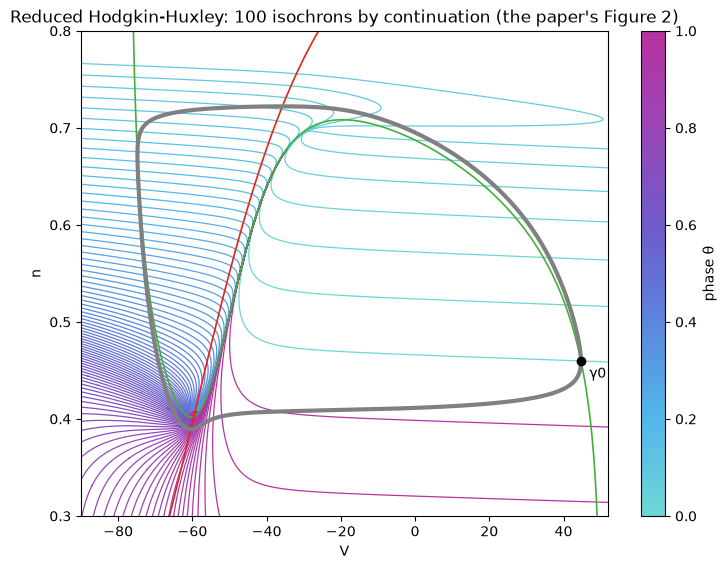

In [10]:
from matplotlib.colors import LinearSegmentedColormap
PHASE = LinearSegmentedColormap.from_list("cyan_magenta", ["#6fd6d6", "#52b6ea", "#5b86dc", "#6f5ac8", "#9a46b6", "#b8329f"])
fig, ax = plt.subplots(figsize=(8.5, 6.3))
for th, r in ISO.items():
    for key, u in r.items():
        ax.plot(u[:, 0], u[:, 1], color=PHASE(th), lw=0.9)
V, W = np.meshgrid(np.linspace(*PLOT[:2], 600), np.linspace(*PLOT[2:], 400))
with np.errstate(all="ignore"):
    am_ = 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10)); bm_ = 4 * np.exp(-(V + 65) / 18)
    an_ = 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10)); bn_ = 0.125 * np.exp(-(V + 65) / 80)
ax.contour(V, W, 10 - 120 * (am_ / (am_ + bm_)) ** 3 * (0.8 - W) * (V - 50) - 36 * W ** 4 * (V + 77) - 0.3 * (V + 54.4),
           [0], colors="#41b13a", linewidths=1.2)
ax.contour(V, W, an_ * (1 - W) - bn_ * W, [0], colors="#e3241b", linewidths=1.2)
ax.plot(POLY[:, 0], POLY[:, 1], color="0.5", lw=3)
ax.plot(*gamma0, "ko"); ax.annotate("γ0", gamma0, xytext=(6, -12), textcoords="offset points")
sm = plt.cm.ScalarMappable(cmap=PHASE, norm=plt.Normalize(0, 1))
fig.colorbar(sm, ax=ax, label="phase θ")
ax.set(xlim=PLOT[:2], ylim=PLOT[2:], xlabel="V", ylabel="n",
       title="Reduced Hodgkin-Huxley: 100 isochrons by continuation (the paper's Figure 2)")
plt.show()

## 7. Checks

**Against brute force.** Take points of the computed isochrons, measure their asymptotic
phase directly from spike times (the method of notebook 01: a network of copies in one
XPP run), and compare with the phase θ_i of the isochron they belong to.

1000 isochron points tested; 901 are in the sensitive set (near x* and along the repelling slow manifold)
well-conditioned points (99): |brute-force phase − θ_i| median 2.6e-05, 99% 6.0e-05, max 6.1e-05


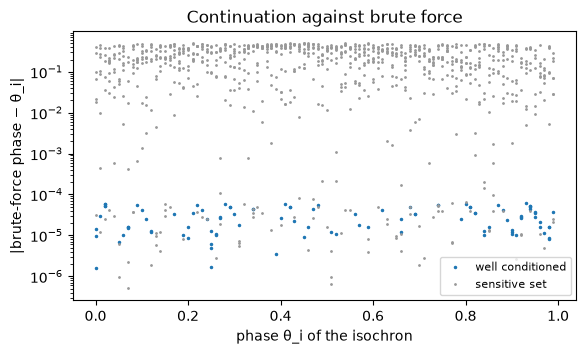

In [11]:
NC = 200
nb_ = ModelBuilder("hh_net")
for sig, expr in FUN:
    nb_.function(sig, expr)
net = (nb_.ode(f"v[0..{NC - 1}]", "iapp-gna*minf(v[j])^3*(0.8-n[j])*(v[j]-ena)-gk*n[j]^4*(v[j]-ek)-gl*(v[j]-el)")
       .ode(f"n[0..{NC - 1}]", "an(v[j])*(1-n[j])-bn(v[j])*n[j]").parameter(**PARS)
       .option(dt=0.01, meth="rk4", bound=1e6, maxstor=400000).load(WORK / "hh_net.ode"))
VTH = -20.0                                        # a spike: V crossing -20 upward
m.set(v=gamma0[0], n=gamma0[1])
r = m.run(keep=False, total=3 * T, dt=0.001)
vv = np.asarray(r["v"]) - VTH; tt = np.asarray(r.t)
i0 = np.nonzero((vv[:-1] < 0) & (vv[1:] >= 0))[0][0]
tc0 = tt[i0] - vv[i0] / (vv[i0 + 1] - vv[i0]) * (tt[i0 + 1] - tt[i0])


def brute_phase(pts, nper=10):
    out = np.full(len(pts), np.nan)
    for s0 in range(0, len(pts), NC):
        chunk = pts[s0:s0 + NC]
        ic = {}
        for j in range(NC):
            p = chunk[j] if j < len(chunk) else chunk[0]
            ic[f"v{j}"], ic[f"n{j}"] = p[0], p[1]
        net.ics.update(ic)
        Ar = net.run(total=nper * T, trans=(nper - 2.5) * T).array
        t, Vv = Ar[:, 0], Ar[:, 1:1 + len(chunk)] - VTH
        for c in range(len(chunk)):
            i = np.nonzero((Vv[:-1, c] < 0) & (Vv[1:, c] >= 0))[0]
            if len(i) >= 2:
                ts = t[i] - Vv[i, c] / (Vv[i + 1, c] - Vv[i, c]) * (t[i + 1] - t[i])
                if abs(ts[-1] - ts[-2] - T) < 1e-3 * T:
                    out[s0 + c] = ((tc0 - ts[-1]) / T) % 1
    return out


def sensitivity(pts, dx=1e-6):
    """largest change of the brute-force phase when a point is moved by 1e-4 mV in V or 1e-6 in n: above
    1e-3, the point is in the sensitive set and its phase cannot be pinned down at the
    accuracy of the computed points"""
    th = brute_phase(pts)
    s = np.zeros(len(pts))
    for mv in ((100 * dx, 0), (-100 * dx, 0), (0, dx), (0, -dx)):
        s = np.fmax(s, np.abs((brute_phase(pts + np.array(mv)) - th + 0.5) % 1 - 0.5))
    return th, s


rng = np.random.default_rng(1)
sample, phase_of_iso = [], []
for th, r_ in ISO.items():
    allp = np.vstack(list(r_.values()))[:, :2]
    inwin = allp[(allp[:, 0] > PLOT[0]) & (allp[:, 0] < PLOT[1]) & (allp[:, 1] > PLOT[2]) & (allp[:, 1] < PLOT[3])]
    pick = inwin[rng.choice(len(inwin), size=min(10, len(inwin)), replace=False)]
    sample.append(pick); phase_of_iso += [th] * len(pick)
sample = np.vstack(sample); phase_of_iso = np.array(phase_of_iso)
bf, sens = sensitivity(sample)
dev = (bf - phase_of_iso + 0.5) % 1 - 0.5
good = ~np.isnan(dev) & (sens < 1e-3)
print(f"{len(sample)} isochron points tested; {(sens >= 1e-3).sum()} are in the sensitive set "
      f"(near x* and along the repelling slow manifold)")
print(f"well-conditioned points ({good.sum()}): |brute-force phase − θ_i| median {np.median(np.abs(dev[good])):.1e}, "
      f"99% {np.percentile(np.abs(dev[good]), 99):.1e}, max {np.abs(dev[good]).max():.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogy(phase_of_iso[good], np.abs(dev[good]) + 1e-12, ".", ms=3, label="well conditioned")
ax.semilogy(phase_of_iso[~good], np.abs(dev[~good]) + 1e-12, ".", ms=2, color="0.6", label="sensitive set")
ax.set(xlabel="phase θ_i of the isochron", ylabel="|brute-force phase − θ_i|",
       title="Continuation against brute force")
ax.legend(fontsize=8)
plt.show()

**No crossings.** Two isochrons of different phases cannot meet. Lines drawn through the
computed points of neighbouring isochrons (θ_i and θ_{i+1}) do appear to cross, but only
inside Γ, near x* and along the middle branch, where neighbouring isochrons are
exponentially close. A random sample of these apparent crossings is tested: if every end
point is in the sensitive set, the "crossing" is below the accuracy of the points; a
crossing between well-conditioned points would be a real error.

In [12]:
def orient(p, q, r):
    return np.sign((q[..., 0] - p[..., 0]) * (r[..., 1] - p[..., 1]) - (q[..., 1] - p[..., 1]) * (r[..., 0] - p[..., 0]))


def crossings(P, Q):
    """the crossing segment pairs of the polylines P and Q, as (P[i], P[i+1], Q[j], Q[j+1])"""
    a0, a1 = P[:-1, None], P[1:, None]
    b0, b1 = Q[None, :-1], Q[None, 1:]
    ia, ib = np.nonzero((orient(a0, a1, b0) * orient(a0, a1, b1) < 0) & (orient(b0, b1, a0) * orient(b0, b1, a1) < 0))
    return np.stack([P[ia], P[ia + 1], Q[ib], Q[ib + 1]], axis=1)


found = []
for i, th in enumerate(THETAS):
    th2 = THETAS[(i + 1) % NPHASE]
    for side in ("in", "out"):
        P = np.vstack([ISO[th][k][:, :2] for k in sorted(ISO[th]) if k.startswith(side)])[::2]
        Q = np.vstack([ISO[th2][k][:, :2] for k in sorted(ISO[th2]) if k.startswith(side)])[::2]
        c = crossings(P, Q)
        if len(c):
            found.append(c)
found = np.vstack(found) if found else np.zeros((0, 4, 2))
n_out = 0
print(f"apparent crossings between neighbouring isochrons: {len(found)}")
if len(found):
    mid = found.mean(axis=1)
    inside = Polygon(POLY).contains_points(mid)
    print(f"  inside Γ: {inside.sum()}, outside Γ: {(~inside).sum()}; "
          f"within 2 mV of x*: {(np.hypot(*((mid - xstar) / SC).T) < 0.02).sum()}")
    sel = found[rng.choice(len(found), size=min(1000, len(found)), replace=False)]
    _, s_end = sensitivity(sel.reshape(-1, 2))
    all_sensitive = (s_end.reshape(-1, 4) >= 1e-3).all(axis=1)
    n_bad = int((~all_sensitive).sum())
    print(f"  of {len(sel)} sampled crossings, {all_sensitive.sum()} have all four end points in the "
          f"sensitive set; {n_bad} involve a well-conditioned point")

apparent crossings between neighbouring isochrons: 716269


  inside Γ: 716269, outside Γ: 0; within 2 mV of x*: 434337


  of 1000 sampled crossings, 999 have all four end points in the sensitive set; 1 involve a well-conditioned point


## What we see

* The picture is the paper's Figure 2: the isochrons crowd on the stretch of Γ along the
  left branch (where the orbit is slow), run off almost horizontally outside Γ, and
  inside bend away from x* and climb along the repelling middle branch of the
  V-nullcline before they return to x* (notebook 02 showed the same structure for
  FitzHugh-Nagumo, on a gentler scale).
* The 0-phase isochron, computed live above, has the paper's excursions (n ≈ 0.68 and
  0.55) and boomerang turns near x* (the paper's Figure 3; see the replication notebooks
  for the full analysis).
* **Checks.** Where the phase is well conditioned, the continuation points agree with the
  brute-force asymptotic phase. Most sampled points lie in the sensitive set: near x* and
  along the repelling slow manifold, where moving a point by 10⁻⁴ mV changes its phase
  by more than 10⁻³ — the paper's "almost phaseless set". The lines drawn between
  neighbouring isochrons appear to cross only inside Γ, in that set, where neighbouring
  isochrons are exponentially close and closer than the spacing of the computed points.
  (In the run saved here: 901 of 1000 sampled points are in the sensitive set; the other
  99 agree with brute force to 6 × 10⁻⁵; 999 of 1000 sampled crossings have all their end
  points in the sensitive set, and the one exception involves a point this test classes
  as well conditioned.)
* The method and its settings are the paper's (η = 10⁻⁴, NTST = 100k, its Table 1); the
  same code computed the FitzHugh-Nagumo isochrons of notebook 02.